In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns  

In [2]:
df = pd.read_csv('used-car-dataset/used_cars_dataset_v2.csv') 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         14993 non-null  str  
 1   model         14993 non-null  str  
 2   Year          14993 non-null  int64
 3   Age           14993 non-null  int64
 4   kmDriven      14905 non-null  str  
 5   Transmission  14993 non-null  str  
 6   Owner         14993 non-null  str  
 7   FuelType      14993 non-null  str  
 8   PostedDate    14993 non-null  str  
 9   AdditionInfo  14993 non-null  str  
 10  AskPrice      14993 non-null  str  
dtypes: int64(2), str(9)
memory usage: 1.3 MB


In [3]:
df.describe()

,Year,Age
count,14993.000000,14993.000000
mean,2016.322150,7.677850
std,4.343017,4.343017
min,1900.000000,0.000000
25%,2014.000000,5.000000
50%,2017.000000,7.000000
75%,2019.000000,10.000000
max,2024.000000,124.000000


In [4]:
df.isna().mean()

Brand           0.000000
model           0.000000
Year            0.000000
Age             0.000000
kmDriven        0.005869
Transmission    0.000000
Owner           0.000000
FuelType        0.000000
PostedDate      0.000000
AdditionInfo    0.000000
AskPrice        0.000000
dtype: float64

In [5]:
df.dropna(inplace=True)

In [6]:
df.isna().mean()

Brand           0.0
model           0.0
Year            0.0
Age             0.0
kmDriven        0.0
Transmission    0.0
Owner           0.0
FuelType        0.0
PostedDate      0.0
AdditionInfo    0.0
AskPrice        0.0
dtype: float64

In [7]:
df.kmDriven

0          98,000 km
1        190000.0 km
2          77,246 km
3          83,500 km
4          45,000 km
            ...     
14988      31,000 km
14989      45,000 km
14990      60,000 km
14991      62,000 km
14992      18,000 km
Name: kmDriven, Length: 14905, dtype: str

In [8]:
df["AskPrice"] = df["AskPrice"].str.replace(r"[^\d.]", "", regex=True).astype(float)
df["kmDriven"] = df["kmDriven"].str.replace(r"[^\d.]", "", regex=True).astype(float)

In [9]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...",195000.0
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0


In [10]:
parts = df["PostedDate"].str.split("-")
df["PostedMonth"] = parts.str[0]
df["PostedYear"] = parts.str[1] 

df["PostedYear"] = 2000 + df["PostedYear"].astype(int)

In [11]:
df["PostedMonth"].value_counts()


PostedMonth
Nov    13180
Dec      751
Oct      655
Sep      171
Aug       76
Jul       32
Jun       21
Apr        8
May        6
Jan        2
Feb        2
Mar        1
Name: count, dtype: int64

In [12]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

month_map = {m: i for i, m in enumerate(months, start=1)}

df["MonthNum"] = df["PostedMonth"].map(month_map)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 14905 entries, 0 to 14992
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         14905 non-null  str    
 1   model         14905 non-null  str    
 2   Year          14905 non-null  int64  
 3   Age           14905 non-null  int64  
 4   kmDriven      14905 non-null  float64
 5   Transmission  14905 non-null  str    
 6   Owner         14905 non-null  str    
 7   FuelType      14905 non-null  str    
 8   PostedDate    14905 non-null  str    
 9   AdditionInfo  14905 non-null  str    
 10  AskPrice      14905 non-null  float64
 11  PostedMonth   14905 non-null  object 
 12  PostedYear    14905 non-null  int64  
 13  MonthNum      14905 non-null  int64  
dtypes: float64(2), int64(4), object(1), str(7)
memory usage: 1.7+ MB


In [14]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols

['Year', 'Age', 'kmDriven', 'AskPrice', 'PostedYear', 'MonthNum']

In [15]:
df["AdditionInfo"].head()

0    Honda City v teck in mint condition, valid gen...
1    Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...
2    Volkswagen Vento 2010-2013 Diesel Breeze, 2010...
3       Maruti Suzuki Swift 2017 Diesel Good Condition
4         Maruti Suzuki Baleno Alpha CVT, 2019, Petrol
Name: AdditionInfo, dtype: str

In [16]:
df.drop(columns=["PostedDate", "PostedMonth", "AdditionInfo"], inplace=True)
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,PostedYear,MonthNum
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,195000.0,2024,11
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,375000.0,2024,7
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,184999.0,2024,11
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,565000.0,2024,11
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,685000.0,2024,11
...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,31000.0,Manual,first,hybrid,575000.0,2024,11
14989,BMW,X1,2017,7,45000.0,Automatic,second,Diesel,1345000.0,2024,12
14990,Maruti Suzuki,New-gen Swift,2011,13,60000.0,Automatic,second,Diesel,160000.0,2024,11
14991,Tata,Zest,2019,5,62000.0,Manual,second,hybrid,380000.0,2024,11


In [17]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
cat_cols

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_8916\2887064932.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

In [18]:
df[cat_cols].nunique()

Brand            42
model           434
Transmission      2
Owner             2
FuelType          4
dtype: int64

Owner
second    0.519356
first     0.480644
Name: count, dtype: float64


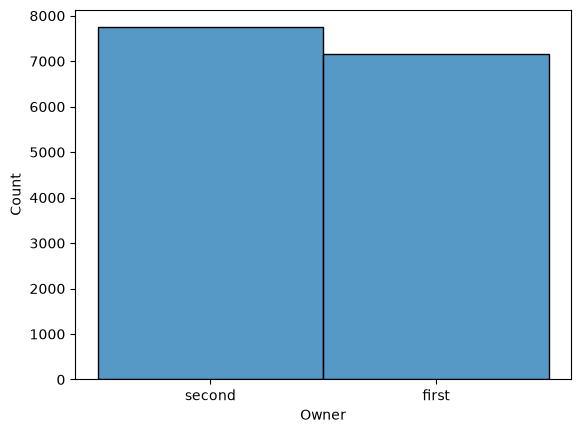

In [19]:
sns.histplot(df["Owner"], bins=50)
print(df["Owner"].value_counts()/len(df))

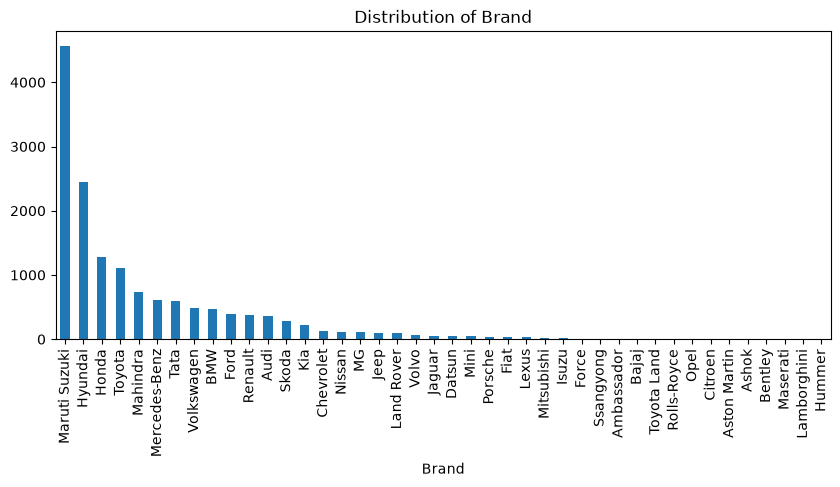

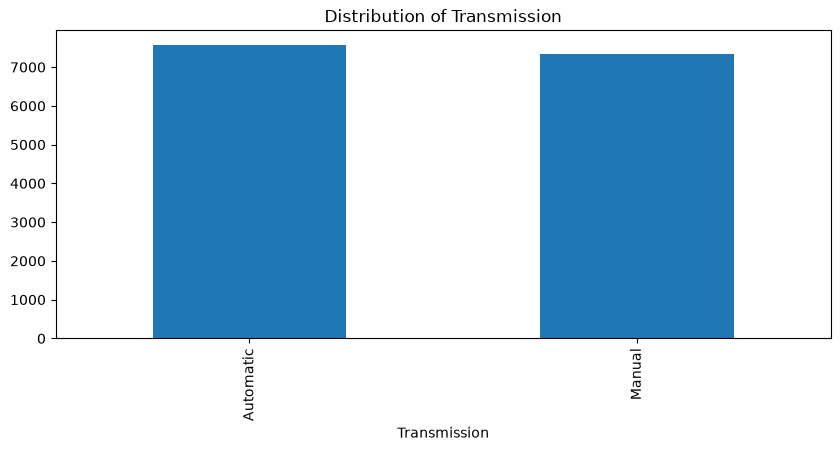

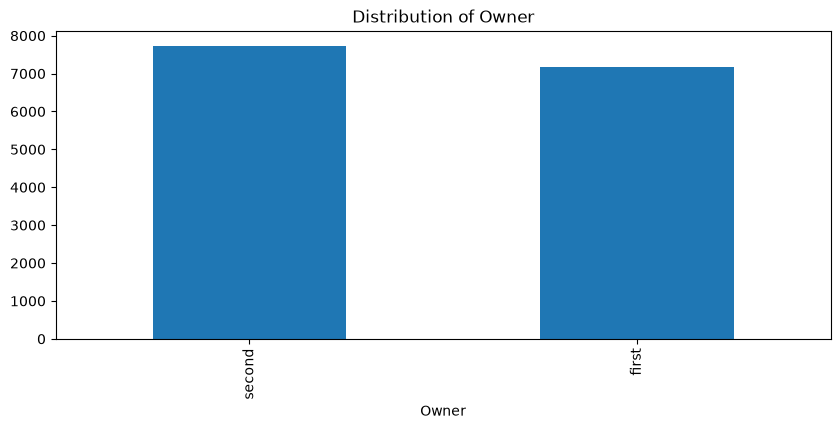

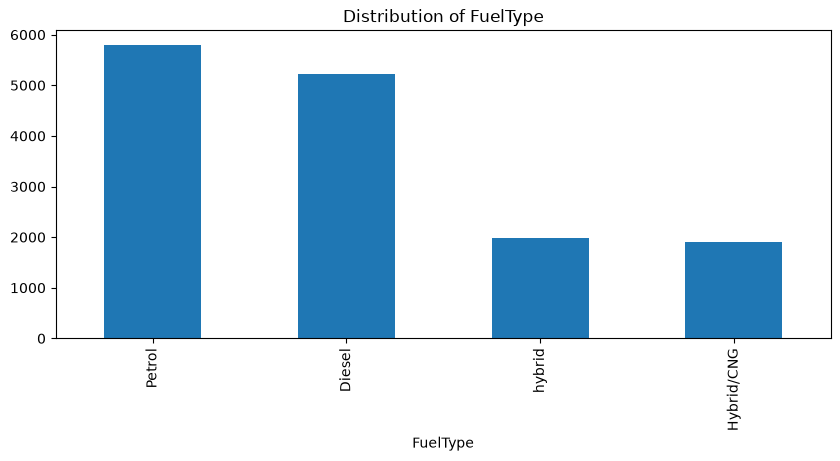

In [20]:
for col in cat_cols:
    if col == "model":
        continue
    plt.figure(figsize=(10, 4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f'Distribution of {col}')
plt.show()

In [21]:
num_cols

['Year', 'Age', 'kmDriven', 'AskPrice', 'PostedYear', 'MonthNum']

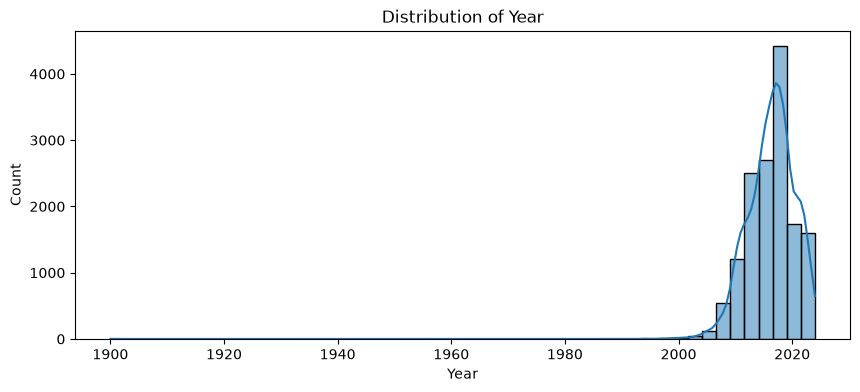

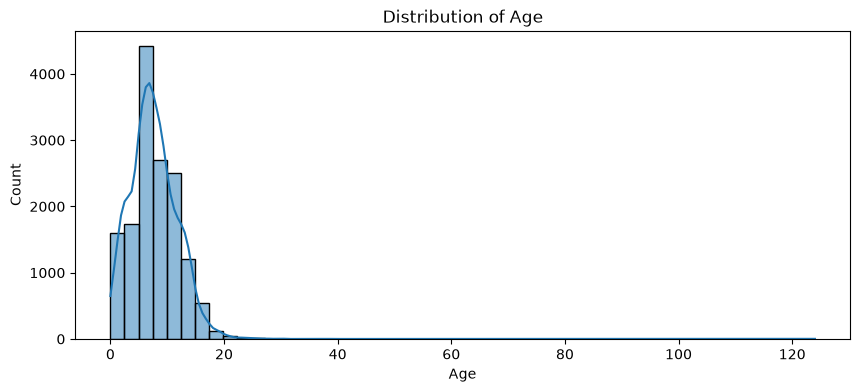

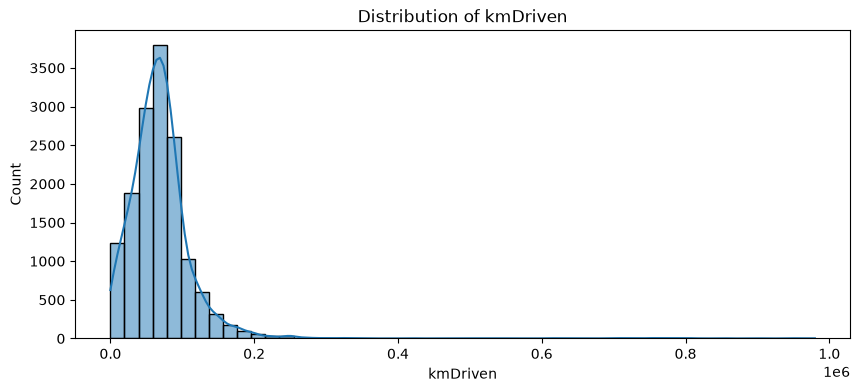

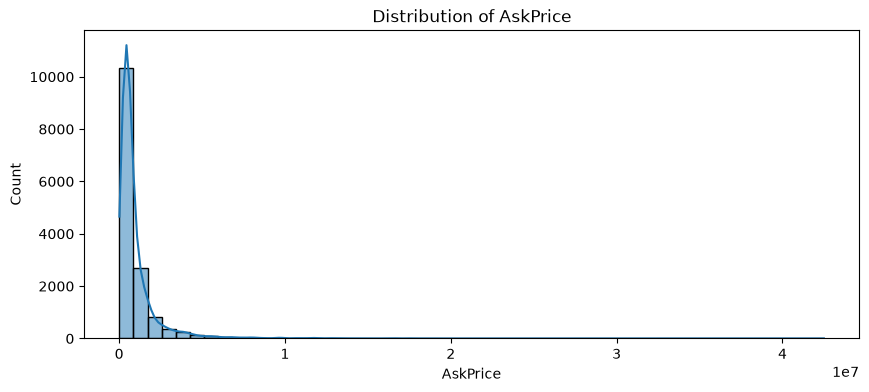

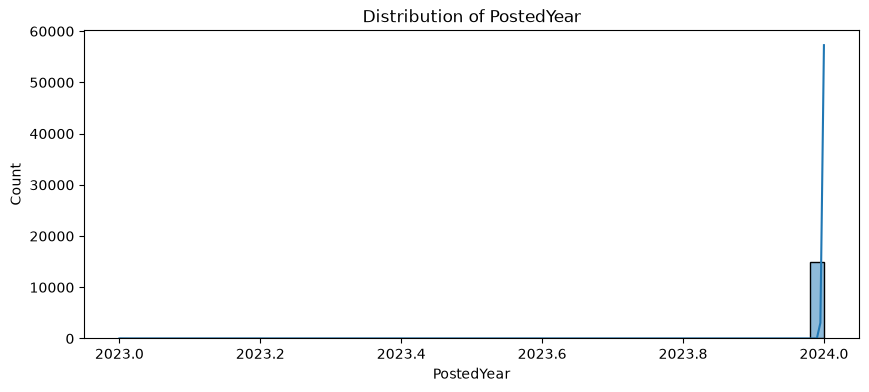

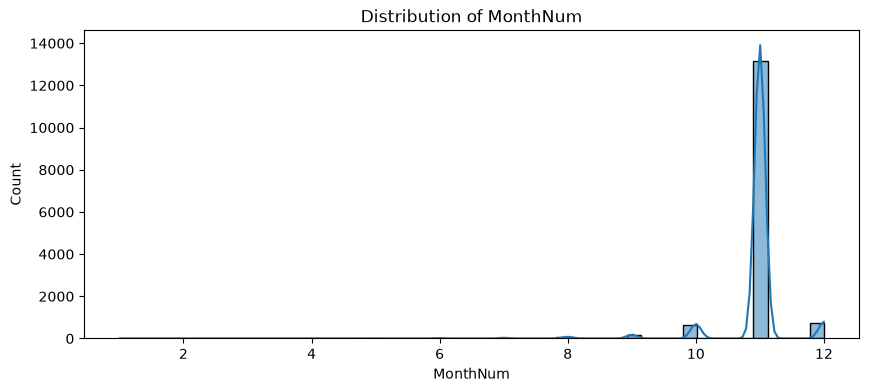

In [22]:
for col in num_cols:
    plt.figure(figsize=(10, 4))
    sns.histplot(df[col], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
plt.show()

<Axes: >

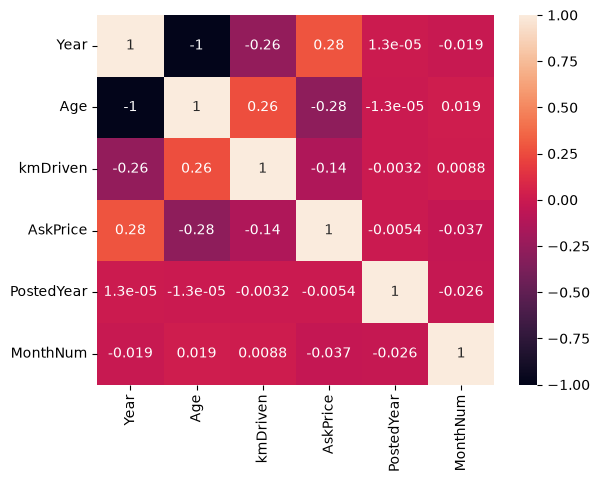

In [23]:
sns.heatmap(df[num_cols].corr(), annot=True)

In [24]:
cat_cols

['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

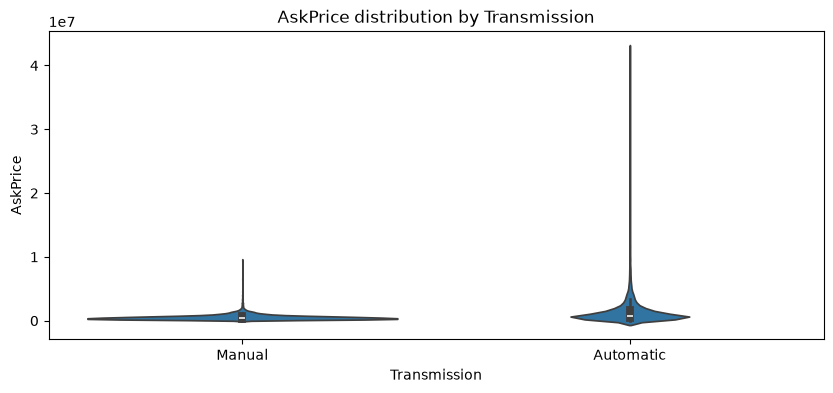

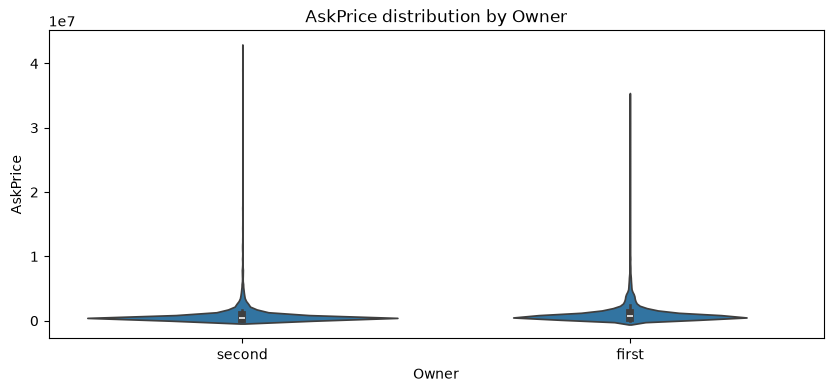

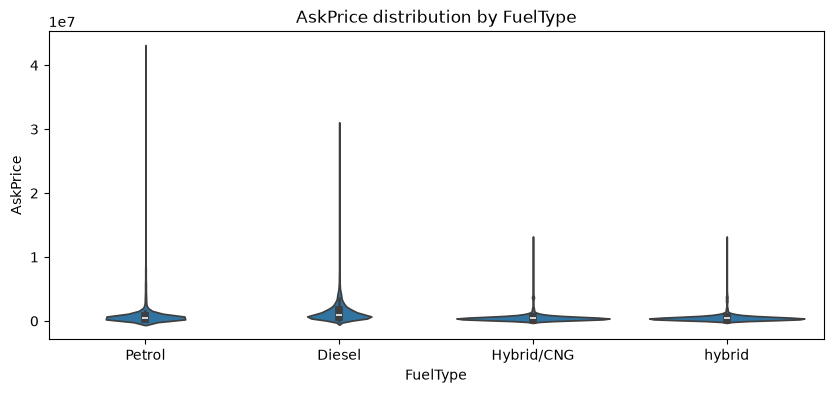

In [25]:
for col in cat_cols:
    if col == "model" or col == "Brand":
        continue
    plt.figure(figsize=(10, 4))
    sns.violinplot(data=df, x=col, y="AskPrice")
    plt.title(f'AskPrice distribution by {col}')
plt.show()

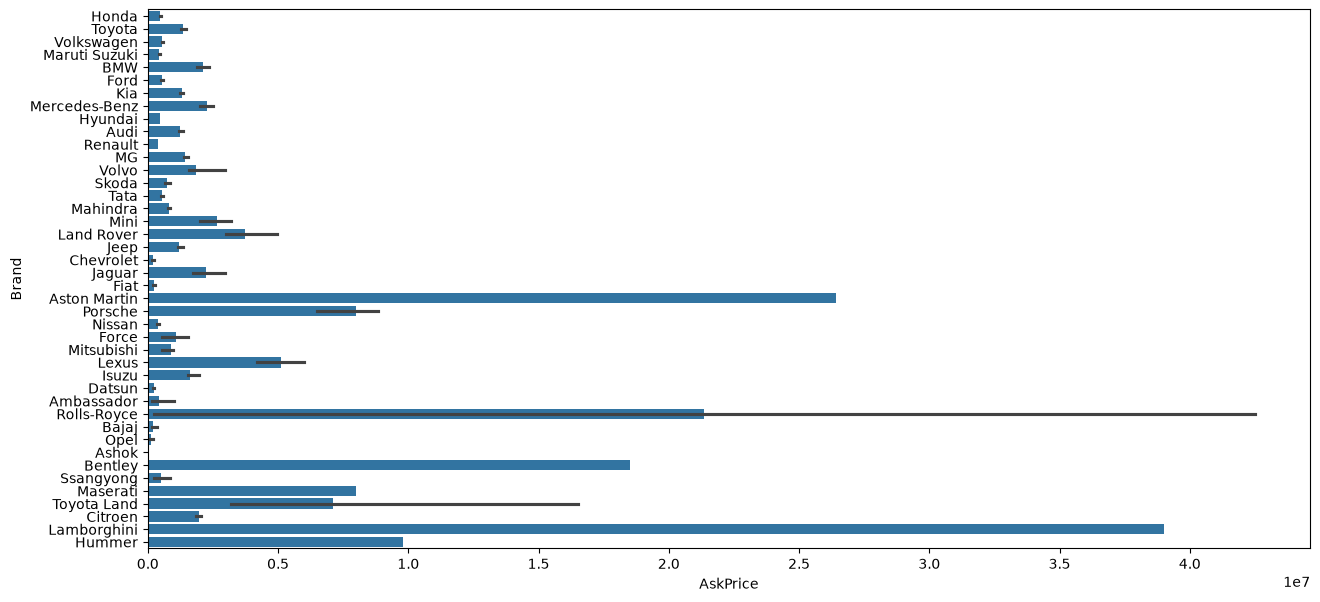

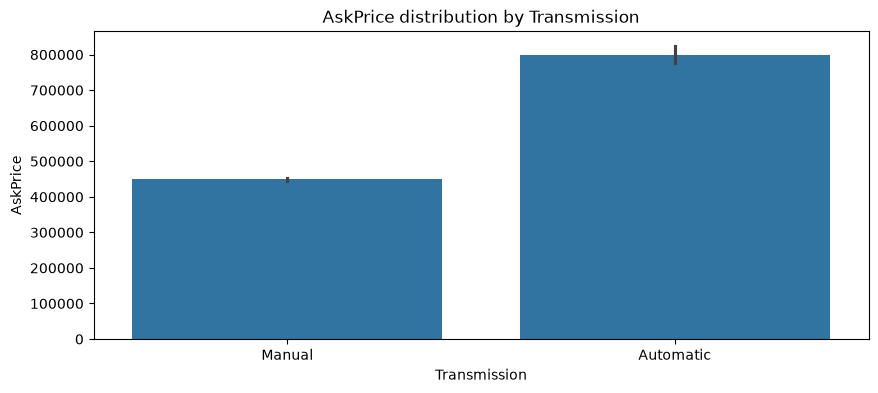

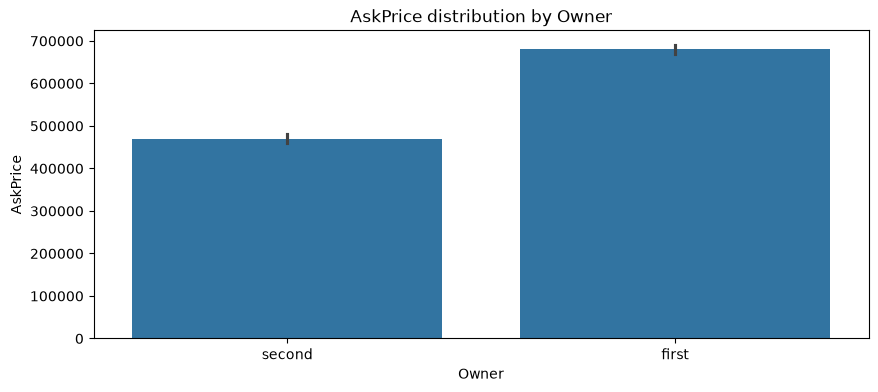

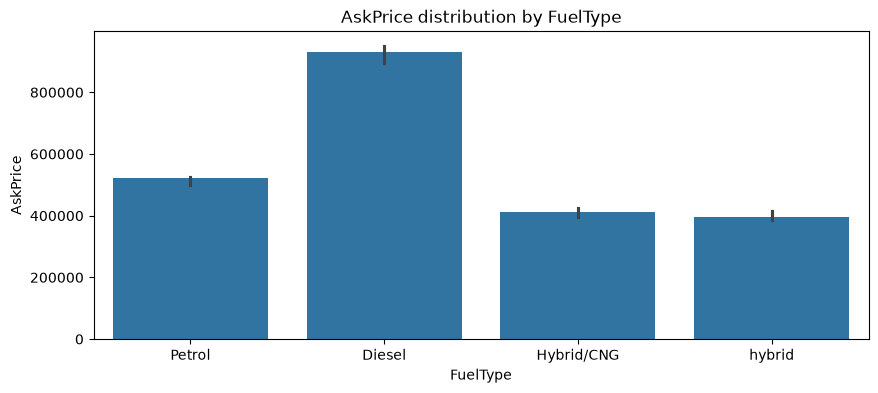

In [26]:
for col in cat_cols:
    if col == "model":
        continue
    if col == "Brand":
        plt.figure(figsize=(15, 7))
        sns.barplot(data=df, x="AskPrice", y=col, estimator=np.median)
        continue
    plt.figure(figsize=(10, 4))
    sns.barplot(data=df, x=col, y="AskPrice", estimator=np.median)
    plt.title(f'AskPrice distribution by {col}')

In [27]:
num_cols

['Year', 'Age', 'kmDriven', 'AskPrice', 'PostedYear', 'MonthNum']

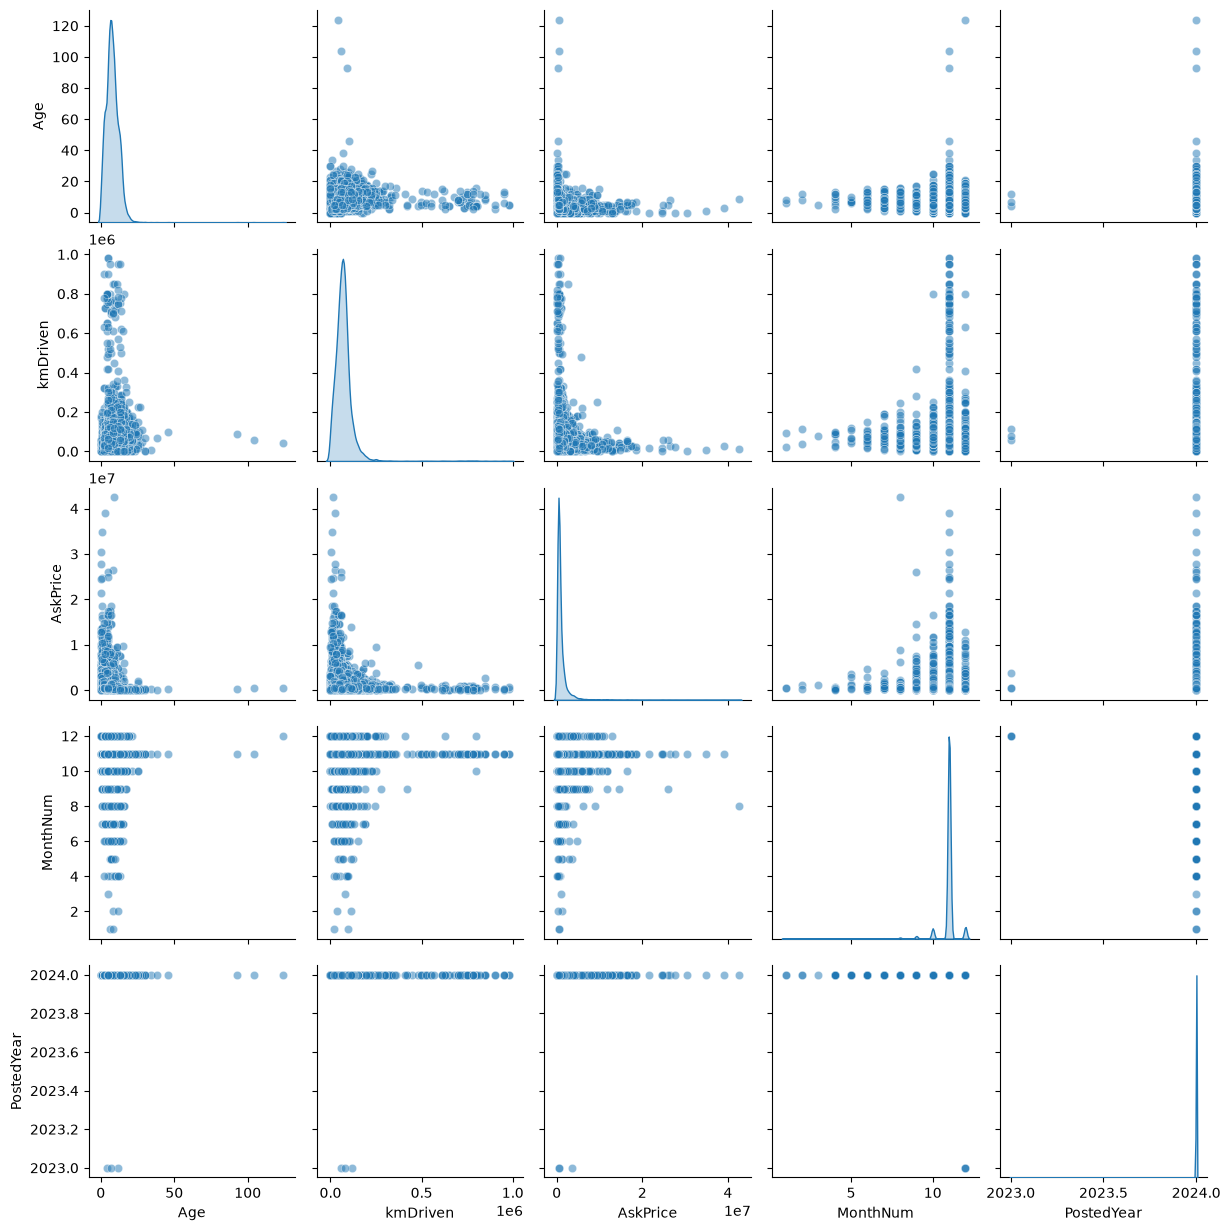

In [28]:
plot_num = ["Age", "kmDriven", "AskPrice", "MonthNum", "PostedYear"]

sns.pairplot(df[plot_num], diag_kind='kde', kind='scatter', plot_kws={'alpha': 0.5})

In [29]:
cat_cols

['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

In [30]:
df.groupby('Brand')['AskPrice'].agg(np.median).sort_values(ascending=False).head(10).reset_index()

,Brand,AskPrice
0,Lamborghini,39000000.0
1,Aston Martin,26400000.0
2,Rolls-Royce,21367500.0
3,Bentley,18500000.0
4,Hummer,9800000.0
5,Maserati,8000000.0
6,Porsche,8000000.0
7,Toyota Land,7100000.0
8,Lexus,5100000.0
9,Land Rover,3750000.0


<Axes: xlabel='AskPrice', ylabel='Brand'>

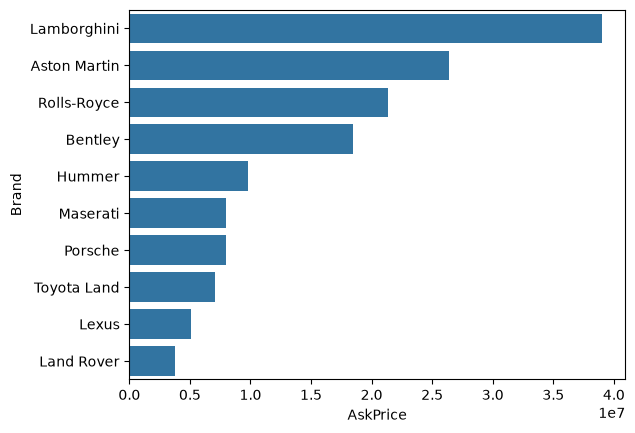

In [31]:
sns.barplot(data=df.groupby('Brand')['AskPrice'].agg(np.median).sort_values(ascending=False).head(10).reset_index(), y='Brand', x='AskPrice')

In [32]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,PostedYear,MonthNum
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,195000.0,2024,11
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,375000.0,2024,7
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,184999.0,2024,11
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,565000.0,2024,11
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,685000.0,2024,11


In [33]:
from pathlib import Path

folder_path = Path("modified_data")
folder_path.mkdir(parents=True, exist_ok=True)

df.to_csv(folder_path / "cleaned_used_cars.csv", index=False)

In [34]:
print("EOF")

EOF
